# Comparação: Baseline vs. Janela Expansiva por Semestre vs. Janela Expansiva + Jittering

Este notebook compara três estratégias de treino/validação para o modelo de previsão de demanda
(`GradientBoostingRegressor` + `RandomForestRegressor` em `VotingRegressor`, com conformal prediction),
para **area1** e **area2**:

1. **Baseline** — exatamente como nos notebooks `Previsao_area1.ipynb` / `Previsao_area2.ipynb`: um único
   modelo treinado com split aleatório 70/30 (treino/calibração) usando todos os anos juntos.
2. **Janela expansiva por semestre** — treina com os semestres já ocorridos e testa no semestre seguinte
   (nunca visto), avançando a janela a cada passo. A calibração do conformal prediction também é feita
   cronologicamente (últimos ~20% do histórico disponível), não por sorteio aleatório.
3. **Janela expansiva por semestre + jittering climático** — igual ao item 2, mas o conjunto de treino de
   cada fold é multiplicado por 6 (original + 5 clones), com ruído gaussiano de escala 0.35× o desvio-padrão
   de cada variável climática (`Precipitacao_mm`, `Temp_max_C`, `Temp_min_C`, `Umid_rel_ar`,
   `Vento_velocidade_ms`, `Vento_rajada_maxima_ms`), respeitando limites físicos (ex.: precipitação ≥ 0,
   umidade em [0,100], `Temp_min_C` ≤ `Temp_max_C`).

**Semestres**: definidos como `Ano*2 + (Mês >= 7)`, ou seja, S1 = jan-jun, S2 = jul-dez. Com 2023-2025 isso
dá 6 blocos → **5 folds** de teste out-of-sample (2023S2, 2024S1, 2024S2, 2025S1, 2025S2).

**Importante (leitura dos resultados):** o baseline é avaliado sobre seu próprio conjunto de calibração
(sorteado aleatoriamente dentre *todos* os anos — ou seja, "vê" o futuro na hora de calibrar). Já os folds
da janela expansiva são avaliados no semestre seguinte, **nunca visto pelo modelo** — uma medida mais realista
do erro que se teria na prática. Por isso o MAE/cobertura do baseline tende a parecer artificialmente melhor;
o objetivo deste notebook é justamente expor essa diferença, não comparar números "iguais para iguais".

Outra ressalva: a filtragem de pratos raros (`>= 5 ocorrências`) e a filtragem de dias problemáticos são
aplicadas sobre a base completa (2023-2025) antes da divisão em folds, replicando o pré-processamento dos
notebooks originais. Isso significa uma pequena fuga de informação do "futuro" para o "passado" nesse passo
específico — não corrigida aqui para manter a comparação fiel ao pipeline existente.


## Configuração e funções comuns

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor, VotingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

np.random.seed(42)

# Parâmetros gerais
N_ESTIMATORS = 200
RANDOM_STATE = 42
ALPHA = 0.05                 # 95% de confiança, igual aos notebooks originais
FRAC_CALIB_BASELINE = 0.3    # como em Previsao_area1/2 (test_size=0.3)
FRAC_CALIB_FOLD = 0.2        # fatia cronológica final do histórico de cada fold, usada para calibração

# Parâmetros do jittering
N_CLONES = 5                 # 5 cópias extras -> treino fica 6x maior
ESCALA_JITTER = 0.35         # ruído = N(0, escala * desvio-padrão da coluna, no próprio treino do fold)

COLS_CLIMA = ['Precipitacao_mm', 'Temp_max_C', 'Temp_min_C',
              'Umid_rel_ar', 'Vento_velocidade_ms', 'Vento_rajada_maxima_ms']

LIMITES_FISICOS = {
    'Precipitacao_mm': (0, None),
    'Umid_rel_ar': (0, 100),
    'Vento_velocidade_ms': (0, None),
    'Vento_rajada_maxima_ms': (0, None),
}

CONFIG = {
    'area1': {
        'csv_path': 'dataatea1clima.csv',
        'onehot_cols': ['Mês', 'Dia_semana', 'Dia_mês', 'prato_principal_1',
                         'prato_principal_2', 'guarnição', 'sobremesa_1', 'refeicao'],
    },
    'area2': {
        'csv_path': 'dataarea2clima.csv',
        'onehot_cols': ['Mês', 'Dia_semana', 'Dia_mês', 'prato_principal_1',
                         'prato_principal_2', 'guarnição', 'sobremesa_1'],
    },
}


In [11]:
def carregar_e_limpar(area):
    """Replica a limpeza feita em Previsao_area1.ipynb / Previsao_area2.ipynb e adiciona
    colunas auxiliares (data_ord, semestre_id) usadas só para particionar os folds."""
    cfg = CONFIG[area]
    data = pd.read_csv(cfg['csv_path'], header=0)
    colunas_clima_faltantes = [col for col in COLS_CLIMA if col not in data.columns]
    if colunas_clima_faltantes:
        raise ValueError(
            f"O CSV de {area} não contém todas as colunas climáticas: "
            f"{colunas_clima_faltantes}. Verifique se o caminho aponta para o arquivo com clima."
        )

    if area == 'area1':
        data = data[data['refeicao'] != 'cafe da manha'].copy()
        data = data.dropna()
        data = data[data['total'] != 0]

    data = data.groupby("guarnição").filter(lambda x: len(x) >= 5)
    data = data.groupby("prato_principal_1").filter(lambda x: len(x) >= 5)
    data = data.groupby("prato_principal_2").filter(lambda x: len(x) >= 5)
    data = data.groupby("sobremesa_1").filter(lambda x: len(x) >= 5)

    data['data_ord'] = pd.to_datetime(dict(year=data['Ano'], month=data['Mês'], day=data['Dia_mês']))
    # S1 = jan-jun, S2 = jul-dez
    data['semestre_id'] = data['Ano'] * 2 + (data['Mês'] >= 7).astype(int)

    data_encoded = pd.get_dummies(data, columns=cfg['onehot_cols'])

    meta_cols = ['total', 'data_ord', 'semestre_id']
    atributos = [c for c in data_encoded.columns if c not in meta_cols]

    X = data_encoded[atributos]
    y = data_encoded['total']
    data_ord = data_encoded['data_ord']
    semestre_id = data_encoded['semestre_id']

    return X, y, data_ord, semestre_id


In [12]:
def jitter_clima(X, y, n_clones=N_CLONES, escala=ESCALA_JITTER, random_state=None):
    """Gera `n_clones` cópias adicionais de X (mantendo y) com ruído gaussiano nas variáveis
    climáticas. O desvio-padrão do ruído de cada coluna é `escala * std(coluna)` calculado
    apenas sobre o X recebido (ou seja, só sobre o treino do fold em questão -- nunca sobre
    calibração ou teste, para não vazar informação nem invalidar a garantia do conformal
    prediction)."""
    rng = np.random.default_rng(random_state)
    cols_presentes = [c for c in COLS_CLIMA if c in X.columns]
    sigmas = {c: X[c].std() * escala for c in cols_presentes}

    X_partes = [X]
    y_partes = [y]
    for _ in range(n_clones):
        Xc = X.copy()
        for c in cols_presentes:
            Xc[c] = Xc[c] + rng.normal(0, sigmas[c], size=len(Xc))
            lo, hi = LIMITES_FISICOS.get(c, (None, None))
            if lo is not None:
                Xc[c] = Xc[c].clip(lower=lo)
            if hi is not None:
                Xc[c] = Xc[c].clip(upper=hi)
        # Temp_min_C não pode ficar maior que Temp_max_C depois do ruído
        if 'Temp_min_C' in Xc.columns and 'Temp_max_C' in Xc.columns:
            trocar = Xc['Temp_min_C'] > Xc['Temp_max_C']
            if trocar.any():
                tmp = Xc.loc[trocar, 'Temp_min_C'].copy()
                Xc.loc[trocar, 'Temp_min_C'] = Xc.loc[trocar, 'Temp_max_C']
                Xc.loc[trocar, 'Temp_max_C'] = tmp
        X_partes.append(Xc)
        y_partes.append(y)

    X_aug = pd.concat(X_partes, ignore_index=True)
    y_aug = pd.concat(y_partes, ignore_index=True)
    return X_aug, y_aug


In [13]:
def treinar_avaliar_fold(X_treino, y_treino, X_calib, y_calib, X_teste, y_teste,
                          jitter=False, escala=ESCALA_JITTER, n_clones=N_CLONES,
                          random_state=RANDOM_STATE, n_estimators=N_ESTIMATORS, alpha=ALPHA):
    """Treina o ensemble (com ou sem jitter no treino), calibra as margens de conformal
    prediction e avalia MAE + cobertura empírica em X_teste/y_teste (nunca usado no treino
    nem na calibração)."""
    if jitter:
        X_tr, y_tr = jitter_clima(X_treino, y_treino, n_clones=n_clones, escala=escala,
                                   random_state=random_state)
    else:
        X_tr, y_tr = X_treino, y_treino

    ensemble = VotingRegressor(
        estimators=[('gb', GradientBoostingRegressor(n_estimators=n_estimators, random_state=random_state)),
                    ('rf', RandomForestRegressor(n_estimators=n_estimators, random_state=random_state))],
        weights=[3, 1]
    )
    ensemble.fit(X_tr, y_tr)

    # --- Calibração (conformal prediction) ---
    y_calib_pred = ensemble.predict(X_calib)
    residuos_calib = np.abs(y_calib.to_numpy() - y_calib_pred)
    mask_trans_calib = (X_calib['dias_desde_ultimas_ferias'] <= 10) | (X_calib['dias_ate_ferias'] <= 10)
    res_trans = residuos_calib[mask_trans_calib.to_numpy()]
    res_norm = residuos_calib[~mask_trans_calib.to_numpy()]

    nivel_confianca = 1 - alpha
    margem_transicao = np.quantile(res_trans, nivel_confianca, method='higher') if len(res_trans) else np.nan
    margem_normal = np.quantile(res_norm, nivel_confianca, method='higher') if len(res_norm) else np.nan

    # --- Avaliação fora da amostra (teste = semestre seguinte, nunca visto) ---
    y_teste_pred = ensemble.predict(X_teste)
    mae_teste = mean_absolute_error(y_teste, y_teste_pred)

    mask_trans_teste = (X_teste['dias_desde_ultimas_ferias'] <= 10) | (X_teste['dias_ate_ferias'] <= 10)
    margem_usada = np.where(mask_trans_teste.to_numpy(), margem_transicao, margem_normal)
    dentro_intervalo = np.abs(y_teste.to_numpy() - y_teste_pred) <= margem_usada
    cobertura = dentro_intervalo.mean()

    return {
        'mae_teste': mae_teste,
        'margem_normal': margem_normal,
        'margem_transicao': margem_transicao,
        'cobertura': cobertura,
        'n_treino': len(X_tr),
        'n_calib': len(X_calib),
        'n_teste': len(X_teste),
    }


In [14]:
def rodar_baseline(X, y, alpha=ALPHA, test_size=FRAC_CALIB_BASELINE, random_state=RANDOM_STATE,
                    n_estimators=N_ESTIMATORS):
    """Reproduz fielmente o treinar_ensemble_conformal() dos notebooks Previsao_area1/2:
    um único modelo, split aleatório treino/calibração, calibração e avaliação sobre a MESMA
    fatia de calibração (não há um 'teste' futuro separado)."""
    X_train, X_calib, y_train, y_calib = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )

    ensemble = VotingRegressor(
        estimators=[('gb', GradientBoostingRegressor(n_estimators=n_estimators, random_state=random_state)),
                    ('rf', RandomForestRegressor(n_estimators=n_estimators, random_state=random_state))],
        weights=[3, 1]
    )
    ensemble.fit(X_train, y_train)

    y_calib_pred = ensemble.predict(X_calib)
    residuos_calib = np.abs(y_calib.to_numpy() - y_calib_pred)
    mask_trans = (X_calib['dias_desde_ultimas_ferias'] <= 10) | (X_calib['dias_ate_ferias'] <= 10)
    res_trans = residuos_calib[mask_trans.to_numpy()]
    res_norm = residuos_calib[~mask_trans.to_numpy()]

    nivel_confianca = 1 - alpha
    margem_transicao = np.quantile(res_trans, nivel_confianca, method='higher') if len(res_trans) else np.nan
    margem_normal = np.quantile(res_norm, nivel_confianca, method='higher') if len(res_norm) else np.nan

    mae_calib = mean_absolute_error(y_calib, y_calib_pred)

    margem_usada = np.where(mask_trans.to_numpy(), margem_transicao, margem_normal)
    dentro_intervalo = residuos_calib <= margem_usada
    cobertura = dentro_intervalo.mean()

    return {
        'mae_teste': mae_calib,          # 'teste' aqui = a própria calibração (ver ressalva no topo)
        'margem_normal': margem_normal,
        'margem_transicao': margem_transicao,
        'cobertura': cobertura,
        'n_treino': len(X_train),
        'n_calib': len(X_calib),
        'n_teste': len(X_calib),
    }


In [15]:
def backtest_expansivo(X, y, data_ord, semestre_id, jitter=False,
                        frac_calib=FRAC_CALIB_FOLD, escala=ESCALA_JITTER, n_clones=N_CLONES,
                        random_state=RANDOM_STATE):
    """Percorre os semestres em ordem cronológica. Em cada passo, treina com todo o histórico
    disponível (semestres anteriores) e testa no semestre seguinte, nunca visto. Dentro do
    histórico de cada fold, separa cronologicamente treino (mais antigo) de calibração
    (fatia final, `frac_calib`)."""
    semestres_ordenados = sorted(semestre_id.unique())
    resultados = []

    for i in range(1, len(semestres_ordenados)):
        semestres_treino = semestres_ordenados[:i]
        semestre_teste = semestres_ordenados[i]

        hist_mask = semestre_id.isin(semestres_treino)
        teste_mask = semestre_id == semestre_teste

        hist_idx = data_ord[hist_mask].sort_values().index
        corte = int(len(hist_idx) * (1 - frac_calib))
        idx_treino = hist_idx[:corte]
        idx_calib = hist_idx[corte:]
        idx_teste = data_ord[teste_mask].sort_values().index

        r = treinar_avaliar_fold(
            X.loc[idx_treino], y.loc[idx_treino],
            X.loc[idx_calib], y.loc[idx_calib],
            X.loc[idx_teste], y.loc[idx_teste],
            jitter=jitter, escala=escala, n_clones=n_clones, random_state=random_state,
        )
        r['fold'] = i
        r['semestre_teste'] = semestre_teste
        resultados.append(r)

    return pd.DataFrame(resultados)


## Função auxiliar para rodar e resumir as três estratégias em uma área

In [16]:
def rodar_comparacao_area(area):
    print(f'=== {area} ===')
    X, y, data_ord, semestre_id = carregar_e_limpar(area)
    print(f'{len(X)} observações, {X.shape[1]} atributos, semestres: {sorted(semestre_id.unique())}')

    # 1) Baseline (como nos notebooks originais)
    print('Rodando baseline...')
    baseline = rodar_baseline(X, y)
    df_baseline = pd.DataFrame([baseline])
    df_baseline.insert(0, 'metodo', 'Baseline (split aleatório)')

    # 2) Janela expansiva por semestre, sem jitter
    print('Rodando janela expansiva (sem jitter)...')
    df_expansivo = backtest_expansivo(X, y, data_ord, semestre_id, jitter=False)
    df_expansivo.insert(0, 'metodo', 'Janela expansiva por semestre')

    # 3) Janela expansiva por semestre, com jitter
    print('Rodando janela expansiva (com jitter climático)...')
    df_expansivo_jitter = backtest_expansivo(X, y, data_ord, semestre_id, jitter=True)
    df_expansivo_jitter.insert(0, 'metodo', 'Janela expansiva + jitter (0.35, 5 clones)')

    return {
        'area': area,
        'baseline': df_baseline,
        'expansivo': df_expansivo,
        'expansivo_jitter': df_expansivo_jitter,
    }


In [17]:
def resumir_resultados(resultado):
    """Agrega os folds de cada método em uma linha de resumo (médias), para comparação direta."""
    linhas = []
    for chave, nome_display in [('baseline', 'Baseline (split aleatório)'),
                                 ('expansivo', 'Janela expansiva por semestre'),
                                 ('expansivo_jitter', 'Janela expansiva + jitter')]:
        df = resultado[chave]
        linhas.append({
            'Método': nome_display,
            'N folds': len(df),
            'MAE médio': df['mae_teste'].mean(),
            'Margem normal média': df['margem_normal'].mean(),
            'Margem transição média': df['margem_transicao'].mean(),
            'Cobertura média': df['cobertura'].mean(),
        })
    return pd.DataFrame(linhas)


## Área 1

Rodando as três estratégias para `area1`. A etapa de janela expansiva com jitter é a mais lenta
(cada fold treina com ~6x mais linhas).

In [18]:
resultado_area1 = rodar_comparacao_area('area1')


=== area1 ===
1363 observações, 200 atributos, semestres: [np.int64(4046), np.int64(4047), np.int64(4048), np.int64(4049), np.int64(4050), np.int64(4051)]
Rodando baseline...
Rodando janela expansiva (sem jitter)...
Rodando janela expansiva (com jitter climático)...


### Resultados por fold — area1

In [10]:
print('--- Baseline ---')
display(resultado_area1['baseline'])

print('--- Janela expansiva (sem jitter) ---')
display(resultado_area1['expansivo'][['fold', 'semestre_teste', 'n_treino', 'n_calib', 'n_teste',
                                       'mae_teste', 'margem_normal', 'margem_transicao', 'cobertura']])

print('--- Janela expansiva (com jitter) ---')
display(resultado_area1['expansivo_jitter'][['fold', 'semestre_teste', 'n_treino', 'n_calib', 'n_teste',
                                              'mae_teste', 'margem_normal', 'margem_transicao', 'cobertura']])


--- Baseline ---


,metodo,mae_teste,margem_normal,margem_transicao,cobertura,n_treino,n_calib,n_teste
0,Baseline (split aleatório),124.649604,330.801254,302.245426,0.9511,954,409,409


--- Janela expansiva (sem jitter) ---


,fold,semestre_teste,n_treino,n_calib,n_teste,mae_teste,margem_normal,margem_transicao,cobertura
0,1,4047,182,46,238,317.011107,397.807406,NaN,0.579832
1,2,4048,372,94,255,188.809106,383.015275,985.827566,0.933333
2,3,4049,576,145,197,160.693846,432.772584,816.365672,0.989848
3,4,4050,734,184,205,163.605944,334.042766,466.806551,0.917073
4,5,4051,898,225,240,125.340719,388.849002,416.335065,0.966667


--- Janela expansiva (com jitter) ---


,fold,semestre_teste,n_treino,n_calib,n_teste,mae_teste,margem_normal,margem_transicao,cobertura
0,1,4047,1092,46,238,289.930824,447.238731,NaN,0.605042
1,2,4048,2232,94,255,183.875912,353.431958,887.291845,0.921569
2,3,4049,3456,145,197,160.541723,395.743031,806.521367,0.994924
3,4,4050,4404,184,205,164.034600,353.988052,489.688604,0.946341
4,5,4051,5388,225,240,123.470310,377.014468,461.643457,0.970833


### Resumo comparativo — area1

In [11]:
resumo_area1 = resumir_resultados(resultado_area1)
display(resumo_area1)


,Método,N folds,MAE médio,Margem normal média,Margem transição média,Cobertura média
0,Baseline (split aleatório),1,124.649604,330.801254,302.245426,0.951100
1,Janela expansiva por semestre,5,191.092145,387.297407,671.333714,0.877351
2,Janela expansiva + jitter,5,184.370674,385.483248,661.286318,0.887742


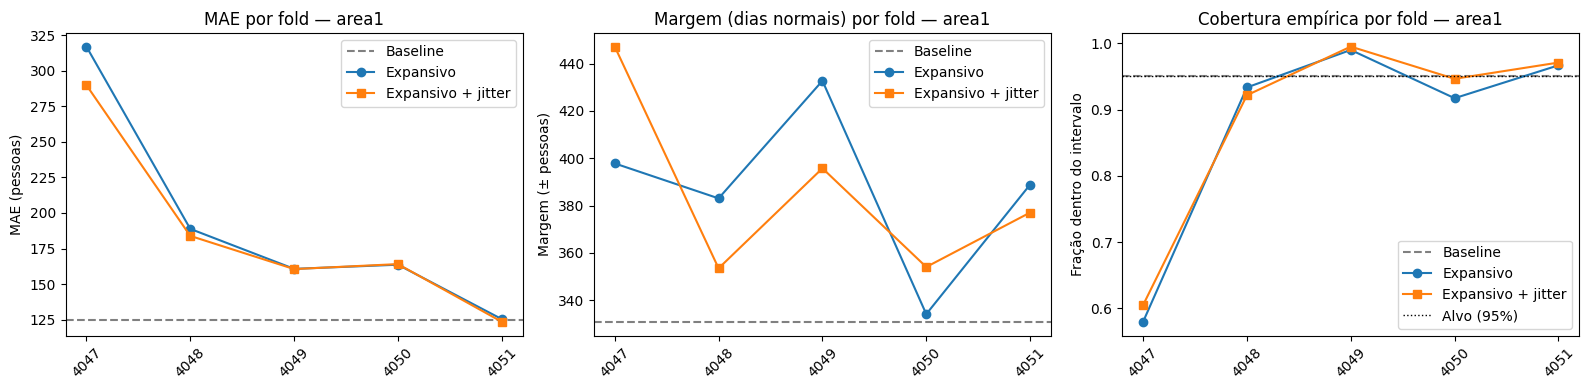

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

folds_labels = resultado_area1['expansivo']['semestre_teste'].astype(str).tolist()

axes[0].axhline(resultado_area1['baseline']['mae_teste'].iloc[0], color='gray', linestyle='--',
                 label='Baseline')
axes[0].plot(folds_labels, resultado_area1['expansivo']['mae_teste'], marker='o', label='Expansivo')
axes[0].plot(folds_labels, resultado_area1['expansivo_jitter']['mae_teste'], marker='s', label='Expansivo + jitter')
axes[0].set_title('MAE por fold — area1')
axes[0].set_ylabel('MAE (pessoas)')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend()

axes[1].axhline(resultado_area1['baseline']['margem_normal'].iloc[0], color='gray', linestyle='--',
                 label='Baseline')
axes[1].plot(folds_labels, resultado_area1['expansivo']['margem_normal'], marker='o', label='Expansivo')
axes[1].plot(folds_labels, resultado_area1['expansivo_jitter']['margem_normal'], marker='s', label='Expansivo + jitter')
axes[1].set_title('Margem (dias normais) por fold — area1')
axes[1].set_ylabel('Margem (± pessoas)')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend()

axes[2].axhline(resultado_area1['baseline']['cobertura'].iloc[0], color='gray', linestyle='--',
                 label='Baseline')
axes[2].plot(folds_labels, resultado_area1['expansivo']['cobertura'], marker='o', label='Expansivo')
axes[2].plot(folds_labels, resultado_area1['expansivo_jitter']['cobertura'], marker='s', label='Expansivo + jitter')
axes[2].axhline(0.95, color='black', linewidth=1, linestyle=':', label='Alvo (95%)')
axes[2].set_title('Cobertura empírica por fold — area1')
axes[2].set_ylabel('Fração dentro do intervalo')
axes[2].tick_params(axis='x', rotation=45)
axes[2].legend()

plt.tight_layout()
plt.savefig('comparacao_area1.png', bbox_inches='tight')
plt.show()


## Área 2

In [13]:
resultado_area2 = rodar_comparacao_area('area2')


=== area2 ===
603 observações, 182 atributos, semestres: [np.int64(4046), np.int64(4047), np.int64(4048), np.int64(4049), np.int64(4050), np.int64(4051)]
Rodando baseline...


Rodando janela expansiva (sem jitter)...


Rodando janela expansiva (com jitter climático)...


### Resultados por fold — area2

In [14]:
print('--- Baseline ---')
display(resultado_area2['baseline'])

print('--- Janela expansiva (sem jitter) ---')
display(resultado_area2['expansivo'][['fold', 'semestre_teste', 'n_treino', 'n_calib', 'n_teste',
                                       'mae_teste', 'margem_normal', 'margem_transicao', 'cobertura']])

print('--- Janela expansiva (com jitter) ---')
display(resultado_area2['expansivo_jitter'][['fold', 'semestre_teste', 'n_treino', 'n_calib', 'n_teste',
                                              'mae_teste', 'margem_normal', 'margem_transicao', 'cobertura']])


--- Baseline ---


,metodo,mae_teste,margem_normal,margem_transicao,cobertura,n_treino,n_calib,n_teste
0,Baseline (split aleatório),51.359307,150.827195,131.739602,0.955801,422,181,181


--- Janela expansiva (sem jitter) ---


,fold,semestre_teste,n_treino,n_calib,n_teste,mae_teste,margem_normal,margem_transicao,cobertura
0,1,4047,63,16,120,161.814801,361.746179,NaN,0.675000
1,2,4048,159,40,112,55.643425,266.832482,330.094571,0.982143
2,3,4049,248,63,93,64.453511,145.104596,43.275901,0.709677
3,4,4050,323,81,85,61.362223,176.991073,156.664089,0.929412
4,5,4051,391,98,114,63.023457,168.973263,197.291204,0.938596


--- Janela expansiva (com jitter) ---


,fold,semestre_teste,n_treino,n_calib,n_teste,mae_teste,margem_normal,margem_transicao,cobertura
0,1,4047,378,16,120,155.206972,361.248594,NaN,0.683333
1,2,4048,954,40,112,56.027505,268.180411,284.189832,0.973214
2,3,4049,1488,63,93,61.982535,148.164975,52.109305,0.731183
3,4,4050,1938,81,85,54.993348,173.585598,158.519471,0.976471
4,5,4051,2346,98,114,60.724437,146.179905,165.107348,0.894737


### Resumo comparativo — area2

In [15]:
resumo_area2 = resumir_resultados(resultado_area2)
display(resumo_area2)


,Método,N folds,MAE médio,Margem normal média,Margem transição média,Cobertura média
0,Baseline (split aleatório),1,51.359307,150.827195,131.739602,0.955801
1,Janela expansiva por semestre,5,81.259483,223.929519,181.831441,0.846966
2,Janela expansiva + jitter,5,77.786960,219.471897,164.981489,0.851788


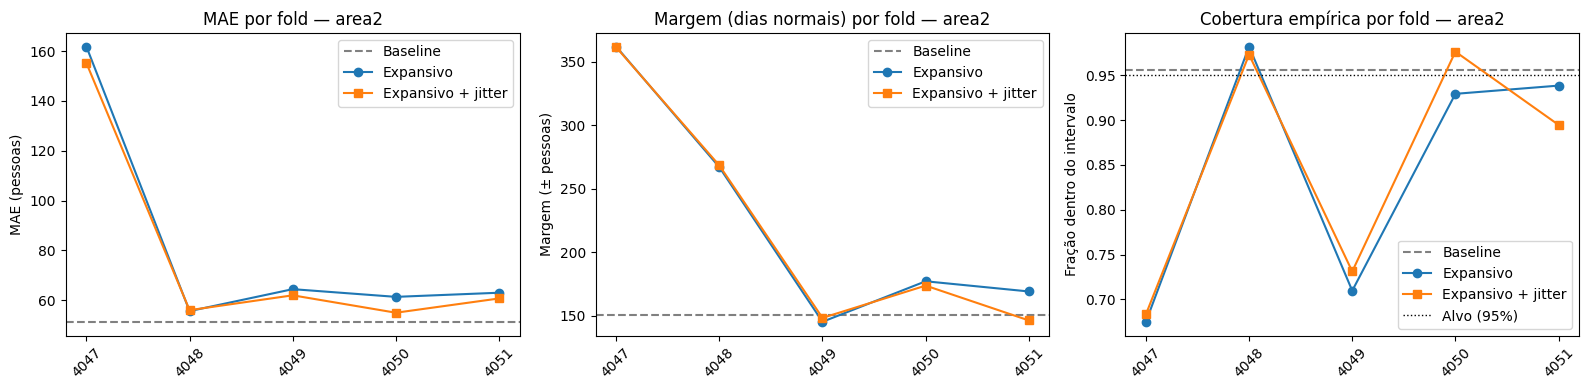

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

folds_labels = resultado_area2['expansivo']['semestre_teste'].astype(str).tolist()

axes[0].axhline(resultado_area2['baseline']['mae_teste'].iloc[0], color='gray', linestyle='--',
                 label='Baseline')
axes[0].plot(folds_labels, resultado_area2['expansivo']['mae_teste'], marker='o', label='Expansivo')
axes[0].plot(folds_labels, resultado_area2['expansivo_jitter']['mae_teste'], marker='s', label='Expansivo + jitter')
axes[0].set_title('MAE por fold — area2')
axes[0].set_ylabel('MAE (pessoas)')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend()

axes[1].axhline(resultado_area2['baseline']['margem_normal'].iloc[0], color='gray', linestyle='--',
                 label='Baseline')
axes[1].plot(folds_labels, resultado_area2['expansivo']['margem_normal'], marker='o', label='Expansivo')
axes[1].plot(folds_labels, resultado_area2['expansivo_jitter']['margem_normal'], marker='s', label='Expansivo + jitter')
axes[1].set_title('Margem (dias normais) por fold — area2')
axes[1].set_ylabel('Margem (± pessoas)')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend()

axes[2].axhline(resultado_area2['baseline']['cobertura'].iloc[0], color='gray', linestyle='--',
                 label='Baseline')
axes[2].plot(folds_labels, resultado_area2['expansivo']['cobertura'], marker='o', label='Expansivo')
axes[2].plot(folds_labels, resultado_area2['expansivo_jitter']['cobertura'], marker='s', label='Expansivo + jitter')
axes[2].axhline(0.95, color='black', linewidth=1, linestyle=':', label='Alvo (95%)')
axes[2].set_title('Cobertura empírica por fold — area2')
axes[2].set_ylabel('Fração dentro do intervalo')
axes[2].tick_params(axis='x', rotation=45)
axes[2].legend()

plt.tight_layout()
plt.savefig('comparacao_area2.png', bbox_inches='tight')
plt.show()


## Comparação final consolidada (area1 + area2)

Tabela única juntando os resumos das duas áreas, para leitura rápida.

In [17]:
resumo_area1_tag = resumo_area1.copy()
resumo_area1_tag.insert(0, 'Área', 'area1')

resumo_area2_tag = resumo_area2.copy()
resumo_area2_tag.insert(0, 'Área', 'area2')

resumo_final = pd.concat([resumo_area1_tag, resumo_area2_tag], ignore_index=True)
resumo_final = resumo_final.round(2)
display(resumo_final)


,Área,Método,N folds,MAE médio,Margem normal média,Margem transição média,Cobertura média
0,area1,Baseline (split aleatório),1,124.65,330.80,302.25,0.95
1,area1,Janela expansiva por semestre,5,191.09,387.30,671.33,0.88
2,area1,Janela expansiva + jitter,5,184.37,385.48,661.29,0.89
3,area2,Baseline (split aleatório),1,51.36,150.83,131.74,0.96
4,area2,Janela expansiva por semestre,5,81.26,223.93,181.83,0.85
5,area2,Janela expansiva + jitter,5,77.79,219.47,164.98,0.85


### Leitura dos resultados

- **MAE médio**: baseline avalia sobre sua própria calibração (dados de todo o período, sorteados
  aleatoriamente); os métodos expansivos avaliam sempre no semestre seguinte, nunca visto. Se o MAE
  do expansivo for maior que o baseline, isso é esperado — reflete o erro real de prever o futuro, não
  uma piora de modelo.
- **Cobertura média**: mostra se a margem calculada na calibração realmente contém ~95% dos casos reais
  do semestre seguinte. Cobertura bem abaixo de 95% na janela expansiva indica que a margem "vista de
  dentro do histórico" não generaliza tão bem para o futuro quanto a garantia teórica do conformal
  prediction sugere sob a suposição de independência/estacionariedade — algo que só aparece com esse tipo
  de backtest cronológico, e que o baseline (splits aleatórios de todos os anos) mascara.
- **Efeito do jitter**: compare `MAE médio` e `Cobertura média` entre "Janela expansiva por semestre" e
  "Janela expansiva + jitter" linha a linha, por área. Ganho de jitter = MAE menor e/ou cobertura mais
  próxima de 95% nos mesmos folds (o jitter não muda os folds, só o treino).
